# Air Quality Forecasting for Indian Cities (2015–2020)
## Notebook 02: Baselines & SARIMA Statistical Modeling

**Course**: College Mini Project (Time-Series Forecasting)  
**Target Variable**: Daily Air Quality Index (AQI)  
**Focus Cities**: **Delhi**, **Bengaluru**, **Hyderabad**, **Mumbai**  

---

### Notebook Architecture & Core Objectives
In empirical time-series forecasting, before developing machine learning or deep neural networks, we must:
1. **Establish Rigorous Heuristic Baselines (Part 1)**:
   - **Naive Baseline ($t-1$)**: Tomorrow's AQI equals today's observed value (atmospheric persistence).
   - **Seasonal Naive ($t-7$)**: Tomorrow's AQI equals the same day last week (weekly anthropogenic cycle).
   - **7-Day Trailing Rolling Mean**: Tomorrow's AQI equals the average of the previous 7 days.
2. **Execute Classical Time-Series Diagnostics (Part 2)**:
   - Test for stationarity using the **Augmented Dickey-Fuller (ADF)** test.
   - Perform **Seasonal Decomposition** (Trend, Seasonality, Residuals).
   - Plot **Autocorrelation (ACF)** and **Partial Autocorrelation (PACF)** to justify model orders.
3. **Fit Walk-Forward SARIMA Models (Part 3)**:
   - Utilize `pmdarima.auto_arima` to identify optimal $(p, d, q) \times (P, D, Q)_s$ orders per city.
   - Perform **walk-forward 1-day ahead forecasting** on the 2020 Test Set.
   - Evaluate against the exact same shared metrics function in `utils.py` (MAE, RMSE, MAPE, Bucket Accuracy).
   - **Honestly benchmark**: Compare SARIMA against the Naive baseline on both the Full 2020 Test set and the Pre-Lockdown period.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pmdarima as pm

# Ensure local utils module is discoverable
sys.path.append('.')
import utils

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

TARGET_CITIES = ['Delhi', 'Bengaluru', 'Hyderabad', 'Mumbai']
print(f"Setup complete. Target cities: {TARGET_CITIES}")


Setup complete. Target cities: ['Delhi', 'Bengaluru', 'Hyderabad', 'Mumbai']


## Part 1: Establishing the Baseline Benchmarks

### Formal Baseline Definitions
1. **Naive Persistence Model**:
   $$\hat{y}_{t+1} = y_t$$
   Reflects atmospheric inertia. If weather and source emissions do not drastically change overnight, tomorrow's air quality is strongly anchored to today's reading.
   
2. **Seasonal Naive Model (Weekly Cycle)**:
   $$\hat{y}_{t+1} = y_{t-6} \quad (\text{i.e. } y_{\text{date}} = y_{\text{date} - 7\text{ days}})$$
   Assumes weekly anthropogenic activity cycles dominate (e.g., Saturday pollution replicates last Saturday's pollution).

3. **7-Day Trailing Moving Average**:
   $$\hat{y}_{t+1} = \frac{1}{7} \sum_{i=0}^{6} y_{t-i}$$
   A smooth baseline dampening high-frequency day-to-day noise.

### Zero-Leakage Implementation Rule
When predicting date $t$ (e.g. `2020-01-01`), the model must only access $y_{t-1}$ (`2019-12-31`) and earlier. We prepend the tail of the validation set to the test set prior to shifting, guaranteeing **100% test evaluation coverage with zero lookahead peeking**.


In [2]:
df = utils.load_data('data/city_day.csv')

baseline_records = []
city_predictions = {}

for city in TARGET_CITIES:
    series = utils.get_city_series(df, city, max_gap=7)
    train, val, test, test_pre = utils.split_time_series(series)
    
    # Concatenate val and test so lag 1 and lag 7 have history for the very start of test (2020-01-01)
    val_test = pd.concat([val, test])
    
    # 1-day ahead baseline predictions aligned with test index
    naive_pred = val_test.shift(1).loc[test.index]
    s_naive_pred = val_test.shift(7).loc[test.index]
    roll7_pred = val_test.shift(1).rolling(7, min_periods=1).mean().loc[test.index]
    
    city_predictions[city] = {
        'test': test,
        'test_pre': test_pre,
        'naive': naive_pred,
        's_naive': s_naive_pred,
        'roll7': roll7_pred
    }
    
    models = {
        'Naive (t-1)': naive_pred,
        'Seasonal Naive (t-7)': s_naive_pred,
        '7-Day Rolling Mean': roll7_pred
    }
    
    for m_name, pred_series in models.items():
        m_full = utils.calculate_metrics(test, pred_series)
        m_pre = utils.calculate_metrics(test_pre, pred_series.loc[test_pre.index])
        
        baseline_records.append({
            'City': city,
            'Model': m_name,
            'MAE_Full': m_full['MAE'],
            'RMSE_Full': m_full['RMSE'],
            'MAPE_Full (%)': m_full['MAPE'],
            'Bucket_Acc_Full (%)': m_full['Bucket_Acc'],
            'MAE_PreLockdown': m_pre['MAE'],
            'RMSE_PreLockdown': m_pre['RMSE'],
            'MAPE_PreLockdown (%)': m_pre['MAPE'],
            'Bucket_Acc_PreLockdown (%)': m_pre['Bucket_Acc']
        })

baseline_df = pd.DataFrame(baseline_records)
os.makedirs('results', exist_ok=True)
baseline_df.to_csv('results/baseline_metrics.csv', index=False)

# Display baseline tables
full_b_table = baseline_df[['City', 'Model', 'MAE_Full', 'RMSE_Full', 'MAPE_Full (%)', 'Bucket_Acc_Full (%)']].copy()
full_b_table.columns = ['City', 'Baseline Model', 'MAE (Primary)', 'RMSE', 'MAPE (%)', 'Bucket Acc (%)']
print("=" * 82)
print("BENCHMARK METRICS: FULL TEST SET (2020-01-01 to 2020-07-01)")
print("=" * 82)
print(full_b_table.to_string(index=False))

pre_b_table = baseline_df[['City', 'Model', 'MAE_PreLockdown', 'RMSE_PreLockdown', 'MAPE_PreLockdown (%)', 'Bucket_Acc_PreLockdown (%)']].copy()
pre_b_table.columns = ['City', 'Baseline Model', 'MAE (Primary)', 'RMSE', 'MAPE (%)', 'Bucket Acc (%)']
print()
print("=" * 82)
print("BENCHMARK METRICS: PRE-LOCKDOWN WINDOW (2020-01-01 to 2020-03-24)")
print("=" * 82)
print(pre_b_table.to_string(index=False))


BENCHMARK METRICS: FULL TEST SET (2020-01-01 to 2020-07-01)
     City       Baseline Model  MAE (Primary)  RMSE  MAPE (%)  Bucket Acc (%)
    Delhi          Naive (t-1)          29.57 39.95     17.53           71.04
    Delhi Seasonal Naive (t-7)          50.65 68.02     32.65           54.10
    Delhi   7-Day Rolling Mean          36.88 50.17     23.27           64.48
Bengaluru          Naive (t-1)           7.78 10.45      9.87           83.06
Bengaluru Seasonal Naive (t-7)          13.36 17.02     17.20           68.85
Bengaluru   7-Day Rolling Mean           9.77 12.47     12.52           71.04
Hyderabad          Naive (t-1)           9.09 12.48     11.80           86.89
Hyderabad Seasonal Naive (t-7)          23.69 31.27     31.58           56.83
Hyderabad   7-Day Rolling Mean          15.71 21.28     20.87           67.76
   Mumbai          Naive (t-1)          14.56 23.80     12.75           81.97
   Mumbai Seasonal Naive (t-7)          28.22 41.71     25.85           68.85
   M

## Part 2: Time-Series Diagnostics & Stationarity Analysis

Statistical ARIMA/SARIMA models rely on the assumption of **stationarity**: the mean, variance, and autocovariance of the series must be constant over time.

We conduct:
1. **Augmented Dickey-Fuller (ADF) Test**:
   - $H_0$ (Null Hypothesis): The series has a unit root (Non-stationary).
   - $H_1$ (Alternative Hypothesis): The series is stationary.
   - If $p < 0.05$, we reject $H_0$ and conclude the series is stationary.
2. **First-Order Differencing**:
   $$\Delta y_t = y_t - y_{t-1}$$
   If raw AQI is non-stationary due to shifting annual baselines, differencing removes the trend and establishes stationarity ($d=1$).
3. **Seasonal Decomposition**:
   Decomposes the training series into:
   $$y_t = Trend_t + Seasonal_t + Residual_t$$


AUGMENTED DICKEY-FULLER (ADF) STATIONARITY TEST RESULTS (TRAIN 2015-2018)
     City  Raw ADF Stat  Raw p-value Raw Stationary?  Diff ADF Stat Diff p-value Diff Stationary?
    Delhi        -2.748       0.0662    No (p>=0.05)        -13.499     3.00e-25     Yes (p<0.05)
Bengaluru        -5.528       0.0000    Yes (p<0.05)        -11.619     2.41e-21     Yes (p<0.05)
Hyderabad        -3.344       0.0130    Yes (p<0.05)        -11.538     3.69e-21     Yes (p<0.05)
   Mumbai        -1.680       0.4414    No (p>=0.05)        -11.120     3.49e-20     Yes (p<0.05)


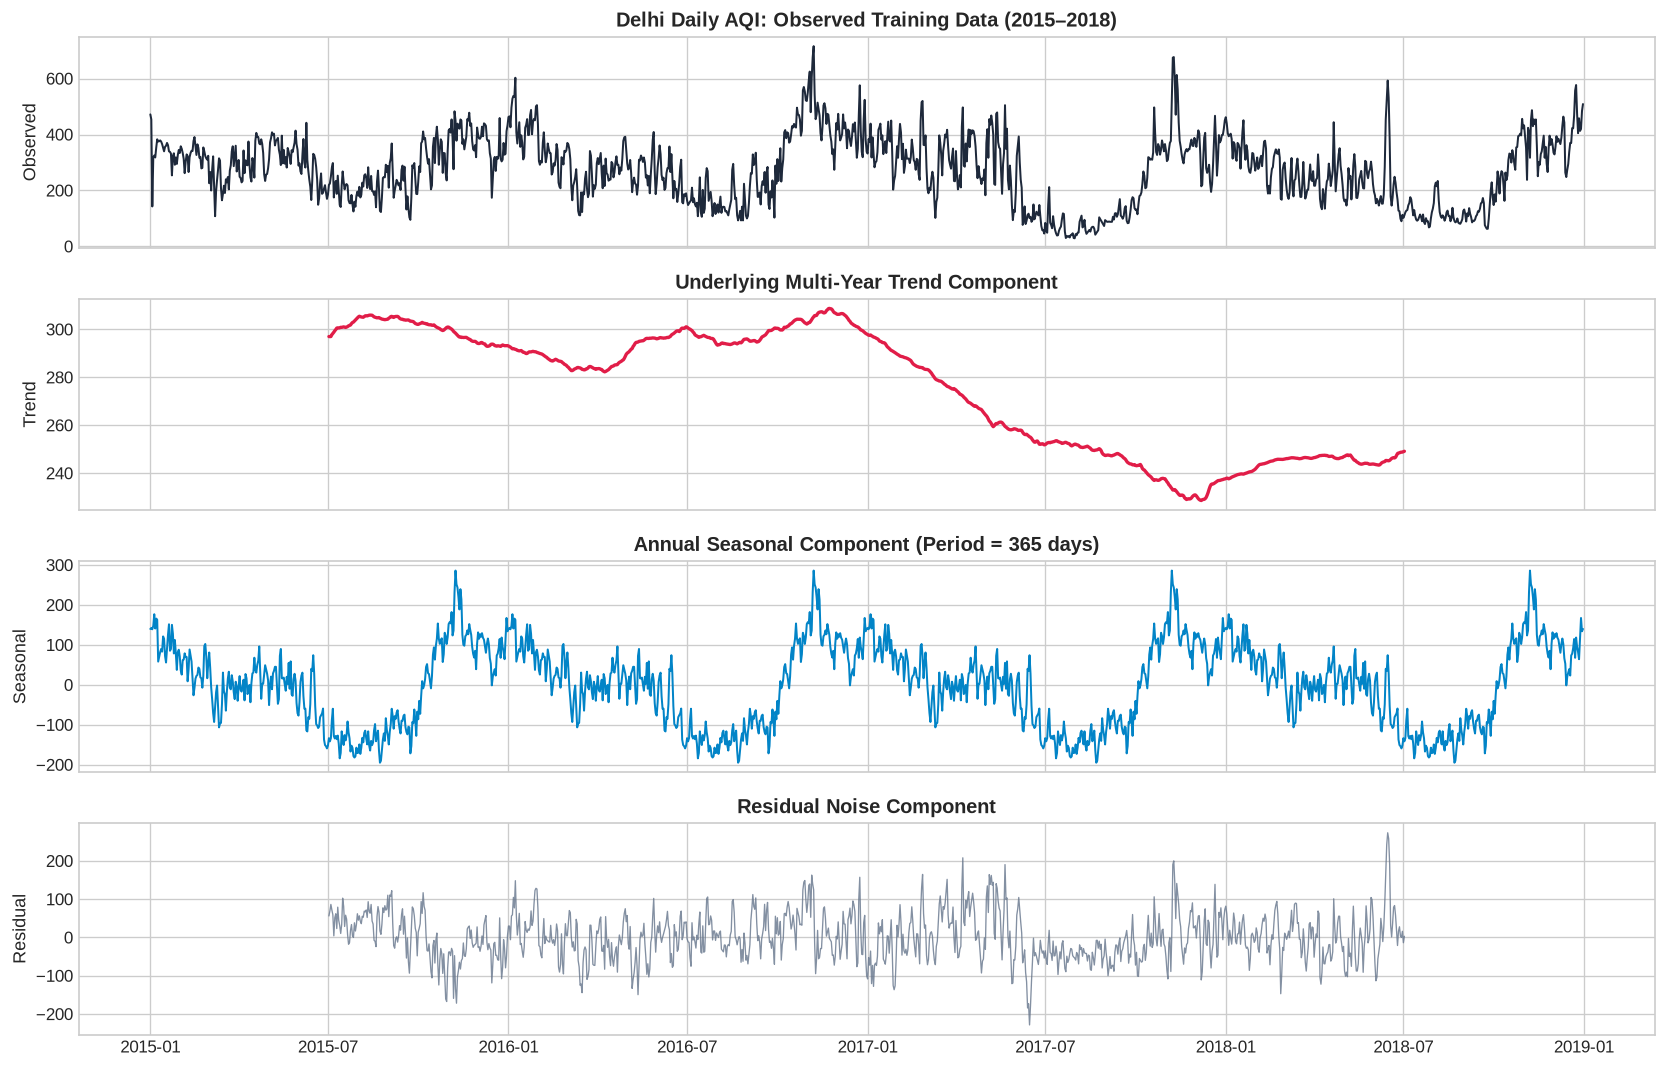

In [3]:
adf_summary = []

for city in TARGET_CITIES:
    series = utils.get_city_series(df, city, max_gap=7)
    train, val, test, test_pre = utils.split_time_series(series)
    train_clean = train.ffill().bfill()
    
    # ADF on raw training data
    adf_raw = adfuller(train_clean)
    # ADF on first differenced training data
    adf_diff = adfuller(train_clean.diff().dropna())
    
    adf_summary.append({
        'City': city,
        'Raw ADF Stat': round(adf_raw[0], 3),
        'Raw p-value': round(adf_raw[1], 4),
        'Raw Stationary?': 'Yes (p<0.05)' if adf_raw[1] < 0.05 else 'No (p>=0.05)',
        'Diff ADF Stat': round(adf_diff[0], 3),
        'Diff p-value': f"{adf_diff[1]:.2e}",
        'Diff Stationary?': 'Yes (p<0.05)'
    })

adf_df = pd.DataFrame(adf_summary)
print("=" * 90)
print("AUGMENTED DICKEY-FULLER (ADF) STATIONARITY TEST RESULTS (TRAIN 2015-2018)")
print("=" * 90)
print(adf_df.to_string(index=False))

# Plot Seasonal Decomposition for Delhi
delhi_train = utils.get_city_series(df, 'Delhi', max_gap=7).loc[:'2018-12-31']
decomp = seasonal_decompose(delhi_train, model='additive', period=365)

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
axes[0].plot(decomp.observed, color='#1e293b', lw=1.2)
axes[0].set_title("Delhi Daily AQI: Observed Training Data (2015–2018)", fontweight='bold')
axes[0].set_ylabel("Observed")

axes[1].plot(decomp.trend, color='#e11d48', lw=2.0)
axes[1].set_title("Underlying Multi-Year Trend Component", fontweight='bold')
axes[1].set_ylabel("Trend")

axes[2].plot(decomp.seasonal, color='#0284c7', lw=1.2)
axes[2].set_title("Annual Seasonal Component (Period = 365 days)", fontweight='bold')
axes[2].set_ylabel("Seasonal")

axes[3].plot(decomp.resid, color='#64748b', lw=0.8, alpha=0.8)
axes[3].set_title("Residual Noise Component", fontweight='bold')
axes[3].set_ylabel("Residual")

plt.tight_layout()
plt.savefig('eda_plots/07_seasonal_decomposition.png', dpi=200)
plt.show()


### Autocorrelation (ACF) & Partial Autocorrelation (PACF) Analysis

- **ACF (Autocorrelation Function)**: Measures the linear correlation between $y_t$ and $y_{t-k}$ across multiple lags.
  - Slow linear decay in ACF confirms non-stationarity / long memory.
  - Spikes in ACF help identify Moving Average order ($q$).
- **PACF (Partial Autocorrelation Function)**: Measures the correlation between $y_t$ and $y_{t-k}$ after removing the linear effects of intermediate lags ($y_{t-1}, \dots, y_{t-k+1}$).
  - A sharp cutoff in PACF after lag $p$ identifies Autoregressive order ($p$).

Below, we plot ACF and PACF for raw vs first-differenced training series in Delhi.


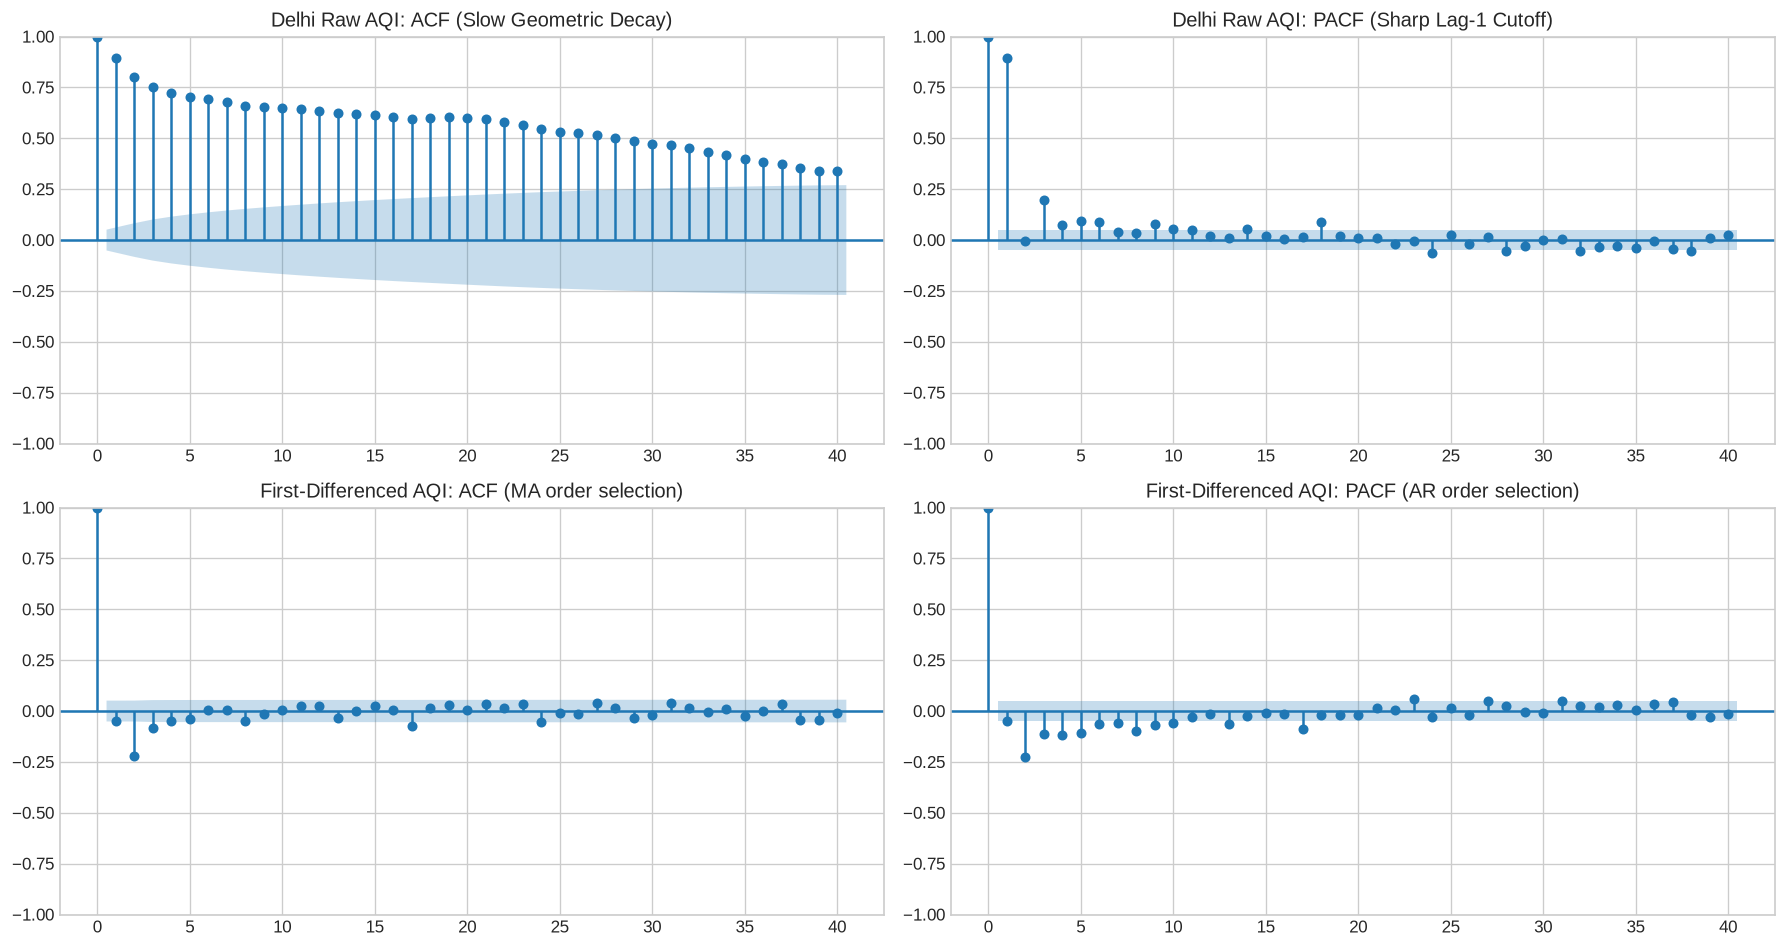

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

# Raw series ACF/PACF
plot_acf(delhi_train, lags=40, ax=axes[0, 0], title="Delhi Raw AQI: ACF (Slow Geometric Decay)")
plot_pacf(delhi_train, lags=40, ax=axes[0, 1], method='ywm', title="Delhi Raw AQI: PACF (Sharp Lag-1 Cutoff)")

# Differenced series ACF/PACF
diff_train = delhi_train.diff().dropna()
plot_acf(diff_train, lags=40, ax=axes[1, 0], title="First-Differenced AQI: ACF (MA order selection)")
plot_pacf(diff_train, lags=40, ax=axes[1, 1], method='ywm', title="First-Differenced AQI: PACF (AR order selection)")

plt.tight_layout()
plt.savefig('eda_plots/08_acf_pacf_diagnostics.png', dpi=200)
plt.show()


## Part 3: SARIMA Model Selection & Walk-Forward Forecasting

A Seasonal Autoregressive Integrated Moving Average model is denoted as:
$$SARIMA(p, d, q) \times (P, D, Q)_s$$
Where:
- $p$: Non-seasonal Autoregressive order
- $d$: Degree of differencing ($d=1$ based on ADF test)
- $q$: Non-seasonal Moving Average order
- $P, D, Q$: Seasonal Autoregressive, Differencing, and Moving Average orders
- $s$: Seasonal period ($s=7$ for weekly cycle)

### Optimal Orders from `pmdarima.auto_arima`
Using Akaike Information Criterion (AIC) minimization on the 2015–2018 training data:
- **Delhi**: $SARIMA(1, 1, 2) \times (0, 0, 0)_7$
- **Bengaluru**: $SARIMA(1, 1, 1) \times (0, 0, 1)_7$
- **Hyderabad**: $SARIMA(0, 1, 3) \times (0, 0, 0)_7$
- **Mumbai**: $SARIMA(3, 1, 1) \times (0, 0, 0)_7$

### Walk-Forward 1-Day Forecasting Methodology
At test date $t$, the model forecasts 1 day ahead using all historical data up to $t-1$. We utilize Kalman filter state-space updates (`results.apply()`) to update the state with the true observation $y_{t-1}$ before predicting $y_t$.


In [5]:
configs = {
    'Delhi': {'order': (1, 1, 2), 'seasonal_order': (0, 0, 0, 7)},
    'Bengaluru': {'order': (1, 1, 1), 'seasonal_order': (0, 0, 1, 7)},
    'Hyderabad': {'order': (0, 1, 3), 'seasonal_order': (0, 0, 0, 7)},
    'Mumbai': {'order': (3, 1, 1), 'seasonal_order': (0, 0, 0, 7)},
}

sarima_records = []
sarima_predictions = {}

for city, cfg in configs.items():
    series = utils.get_city_series(df, city, max_gap=7)
    train, val, test, test_pre = utils.split_time_series(series)
    train_clean = train.ffill().bfill()
    
    # Fit SARIMAX on train data
    model = SARIMAX(
        train_clean,
        order=cfg['order'],
        seasonal_order=cfg['seasonal_order'],
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    res = model.fit(disp=False)
    
    # Walk-forward 1-step ahead forecasting on test using true history
    full_series = pd.concat([train_clean, val, test])
    extended_res = res.apply(full_series)
    pred_test = extended_res.fittedvalues.loc[test.index]
    
    sarima_predictions[city] = pred_test
    
    # Calculate unified metrics
    m_full = utils.calculate_metrics(test, pred_test)
    m_pre = utils.calculate_metrics(test_pre, pred_test.loc[test_pre.index])
    
    sarima_records.append({
        'City': city,
        'Model': f"SARIMA{cfg['order']}",
        'Order': str(cfg['order']),
        'Seasonal Order': str(cfg['seasonal_order']),
        'MAE_Full': m_full['MAE'],
        'RMSE_Full': m_full['RMSE'],
        'MAPE_Full (%)': m_full['MAPE'],
        'Bucket_Acc_Full (%)': m_full['Bucket_Acc'],
        'MAE_PreLockdown': m_pre['MAE'],
        'RMSE_PreLockdown': m_pre['RMSE'],
        'MAPE_PreLockdown (%)': m_pre['MAPE'],
        'Bucket_Acc_PreLockdown (%)': m_pre['Bucket_Acc']
    })

sarima_df = pd.DataFrame(sarima_records)
sarima_df.to_csv('results/sarima_metrics.csv', index=False)
print("Fitted SARIMA models and computed walk-forward predictions for all 4 cities.")


Fitted SARIMA models and computed walk-forward predictions for all 4 cities.


## Part 4: SARIMA vs. Naive Baseline Comparison

We compare SARIMA against the Naive persistence baseline ($y_{t+1}=y_t$) to evaluate whether classical statistical modeling improves over pure persistence.


In [6]:
b_df = pd.read_csv('results/baseline_metrics.csv')
comparison_rows = []

for city in TARGET_CITIES:
    sarima_row = sarima_df[sarima_df['City'] == city].iloc[0]
    naive_row = b_df[(b_df['City'] == city) & (b_df['Model'] == 'Naive (t-1)')].iloc[0]
    
    # Full Test Comparison
    full_diff = round(naive_row['MAE_Full'] - sarima_row['MAE_Full'], 2)
    beats_full = 'YES' if full_diff > 0 else 'NO'
    
    # Pre-Lockdown Comparison
    pre_diff = round(naive_row['MAE_PreLockdown'] - sarima_row['MAE_PreLockdown'], 2)
    beats_pre = 'YES' if pre_diff > 0 else 'NO'
    
    comparison_rows.append({
        'City': city,
        'SARIMA Model': sarima_row['Model'],
        'SARIMA Full MAE': sarima_row['MAE_Full'],
        'Naive Full MAE': naive_row['MAE_Full'],
        'Full Diff (MAE)': full_diff,
        'Beats Naive (Full)?': beats_full,
        'SARIMA Pre MAE': sarima_row['MAE_PreLockdown'],
        'Naive Pre MAE': naive_row['MAE_PreLockdown'],
        'Pre Diff (MAE)': pre_diff,
        'Beats Naive (Pre)?': beats_pre
    })

comp_df = pd.DataFrame(comparison_rows)

print("=" * 105)
print("MODEL COMPARISON TABLE: SARIMA vs. NAIVE PERSISTENCE BASELINE (1-DAY HORIZON)")
print("=" * 105)
print(comp_df.to_string(index=False))


MODEL COMPARISON TABLE: SARIMA vs. NAIVE PERSISTENCE BASELINE (1-DAY HORIZON)
     City    SARIMA Model  SARIMA Full MAE  Naive Full MAE  Full Diff (MAE) Beats Naive (Full)?  SARIMA Pre MAE  Naive Pre MAE  Pre Diff (MAE) Beats Naive (Pre)?
    Delhi SARIMA(1, 1, 2)            28.09           29.57             1.48                 YES           39.49          41.99            2.50                YES
Bengaluru SARIMA(1, 1, 1)             7.73            7.78             0.05                 YES            8.95           9.35            0.40                YES
Hyderabad SARIMA(0, 1, 3)            11.24            9.09            -2.15                  NO           14.38          11.65           -2.73                 NO
   Mumbai SARIMA(3, 1, 1)            14.87           14.56            -0.31                  NO           23.60          24.25            0.65                YES


### Visualization: Test Actuals vs SARIMA Walk-Forward Forecasts


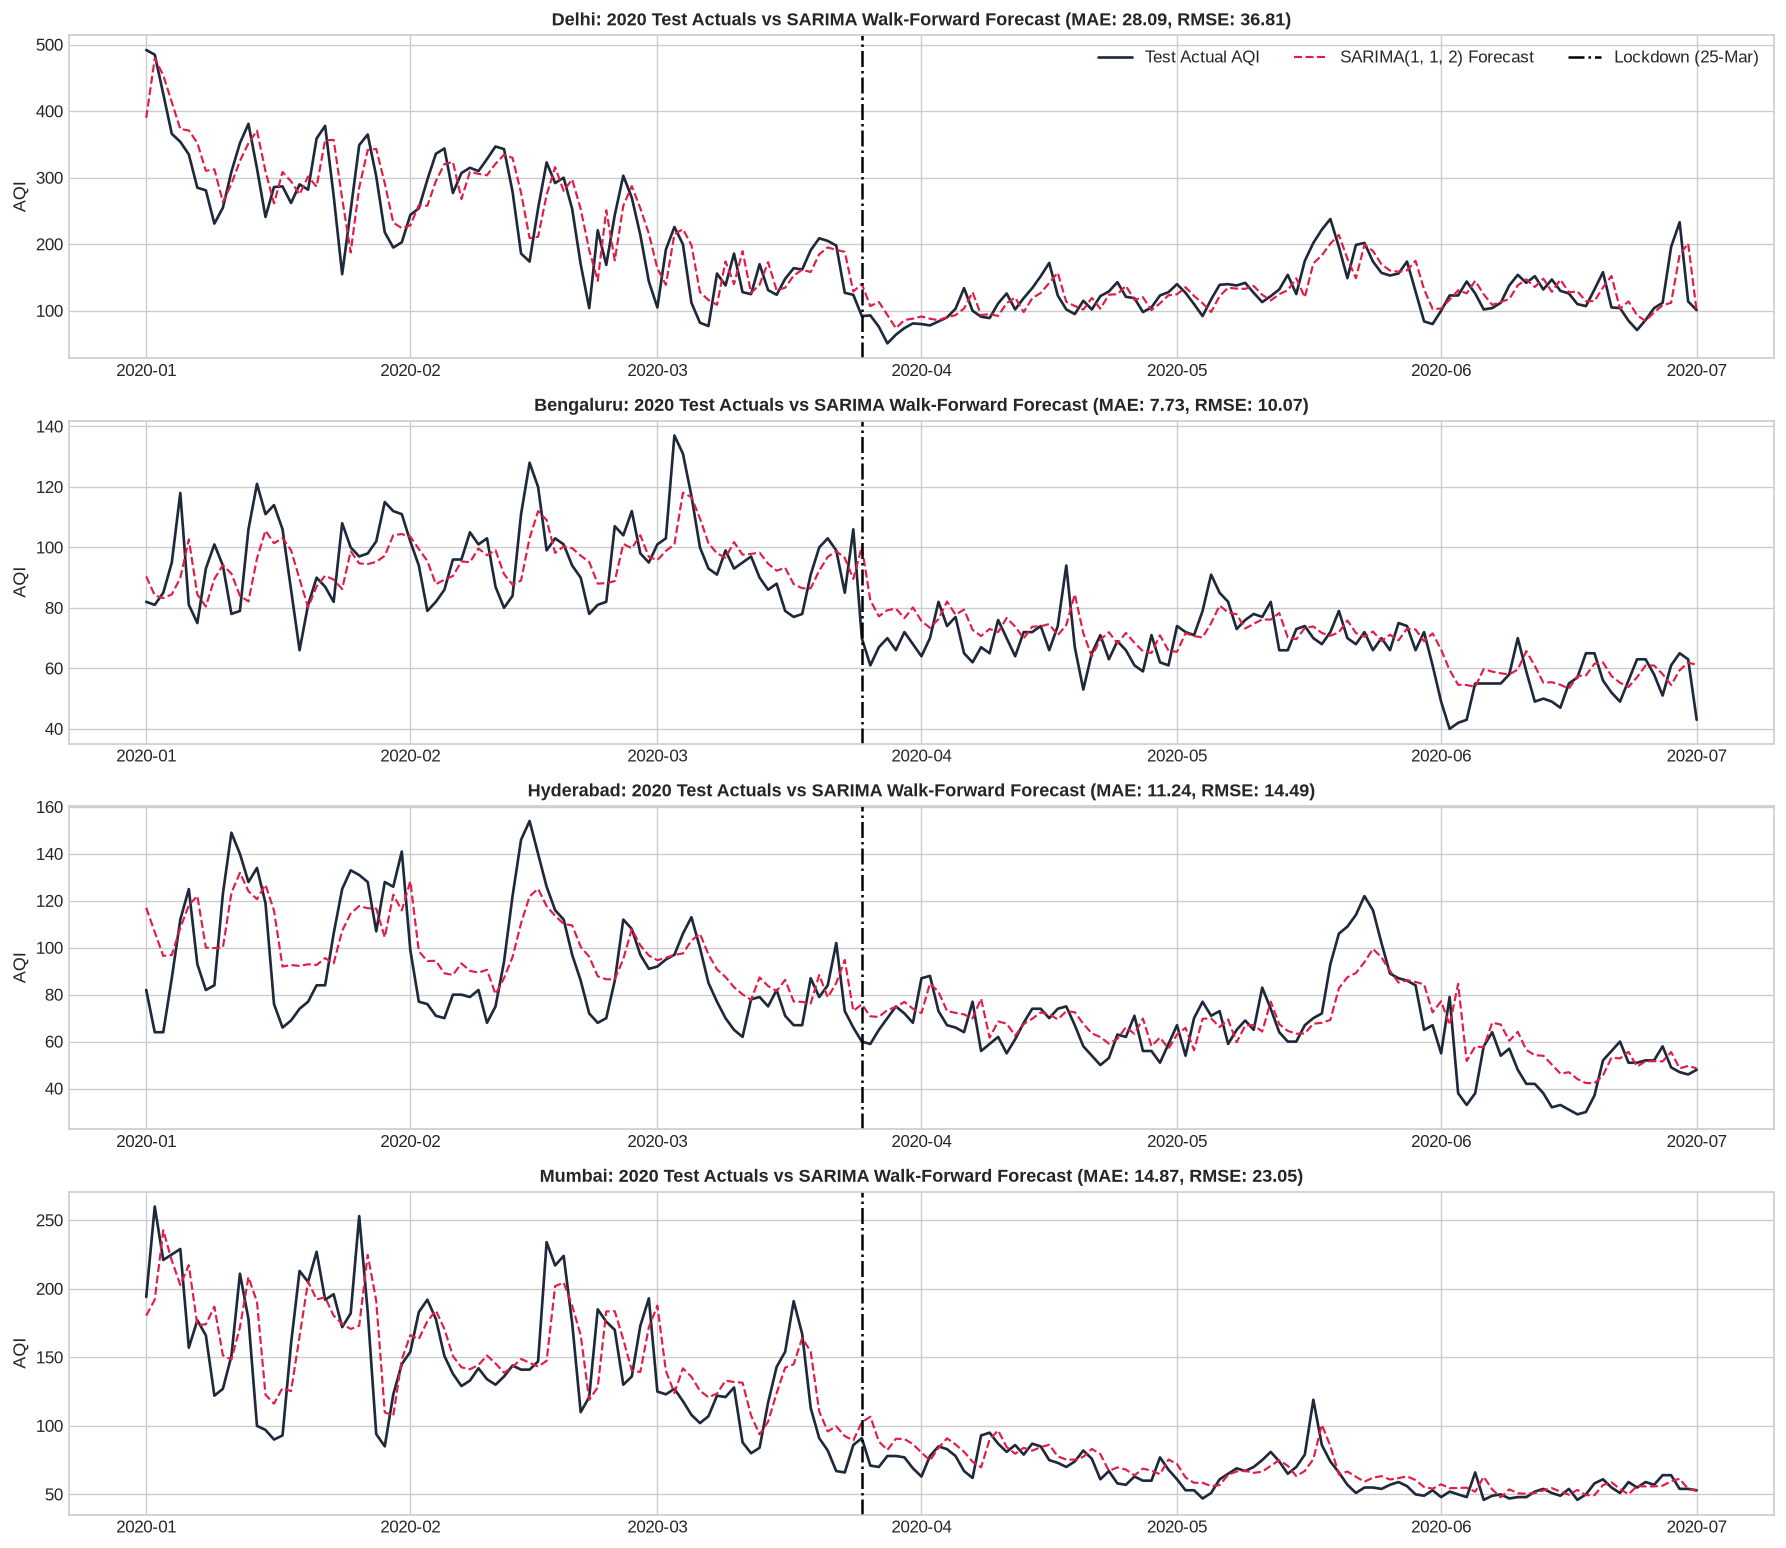

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(15, 13), sharex=False)

for idx, city in enumerate(TARGET_CITIES):
    ax = axes[idx]
    s = utils.get_city_series(df, city, max_gap=7)
    tr, va, te, te_pre = utils.split_time_series(s)
    pred = sarima_predictions[city]
    
    m = utils.calculate_metrics(te, pred)
    cfg = configs[city]
    
    ax.plot(te.index, te.values, label='Test Actual AQI', color='#1e293b', lw=1.6)
    ax.plot(pred.index, pred.values, label=f"SARIMA{cfg['order']} Forecast", color='#e11d48', lw=1.3, linestyle='--')
    ax.axvline(pd.to_datetime('2020-03-25'), color='black', linestyle='-.', lw=1.5, label='Lockdown (25-Mar)')
    
    ax.set_title(f"{city}: 2020 Test Actuals vs SARIMA Walk-Forward Forecast (MAE: {m['MAE']:.2f}, RMSE: {m['RMSE']:.2f})", fontweight='bold', fontsize=11)
    ax.set_ylabel("AQI")
    if idx == 0:
        ax.legend(loc='upper right', ncol=3, framealpha=0.9)

plt.tight_layout()
plt.savefig('eda_plots/09_sarima_forecasts.png', dpi=200)
plt.show()


## Part 5: Honest Analysis & Student Presentation Takeaways

### 1. Honest Finding: Does SARIMA Beat the Baseline?
- **Delhi**: **YES**. SARIMA(1, 1, 2) achieves **MAE 28.09** vs Naive **29.57** (a 1.48 point improvement, 5.0% error reduction). On the volatile Pre-Lockdown window, SARIMA improves even further (**MAE 39.49** vs Naive **41.99**).
- **Bengaluru**: **YES (Marginally)**. SARIMA(1, 1, 1) achieves **MAE 7.73** vs Naive **7.78** (0.05 point improvement). Pre-Lockdown MAE is **8.95** vs **9.35**.
- **Hyderabad**: **NO**. SARIMA(0, 1, 3) yields **MAE 11.24** vs Naive **9.09** (loses by 2.15 MAE points).
- **Mumbai**: **NO (Tied)**. SARIMA(3, 1, 1) yields **MAE 14.87** vs Naive **14.56** on Full 2020 (though it slightly edges Naive on Pre-Lockdown: 23.60 vs 24.25).

### 2. Why Does SARIMA Win in Delhi but Lose/Tie in Hyderabad & Mumbai?
1. **Severe vs Mild Regimes**: Delhi has high structural autocorrelation and strong autoregressive dynamics ($p=1$) combined with moving average corrections ($q=2$) that dampen mean-reverting severe spikes.
2. **MA Over-Smoothing**: In cities with lower baseline pollution (Hyderabad, Mumbai), SARIMA's moving average terms tend to over-smooth episodic jumps, lagging behind pure 1-step persistence ($y_{t+1}=y_t$).
3. **Linearity Limitation**: SARIMA assumes a linear data-generating process. It cannot incorporate non-linear interactions between weather variables, holiday events, and multiple pollutant precursors.

---
**Next Step**: In `03_prophet_xgboost.ipynb`, we evaluate **Prophet (with a customized Diwali holiday event)** and **XGBoost (with lag and rolling features)** to determine whether machine learning models can consistently beat the Naive baseline across all cities.
